# Exploratory Data Analysis (EDA)

In this notebook, we analyze the cleaned dermatology dataset to understand the distribution of diseases, patient demographics, symptoms, and relationships between important health variables.

The goal of EDA is to identify patterns, trends, correlations and insights that help build a better machine learning model.

In [1]:
# Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display Settings
pd.set_option("display.max_columns", None)

# Plot Style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,5)
plt.rcParams["font.size"] = 12

## Load the Cleaned Dataset

The cleaned dataset contains 6,735 patient records with demographic details, symptoms, lifestyle factors, health measurements and the target variable (`disease`).

In [2]:
df = pd.read_csv("../data/dermatology_cleaned_dataset.csv")

print("Shape of Dataset:", df.shape)

df.head()

Shape of Dataset: (6735, 27)


,patient_id,gender,body_area,itching_level,rash_type,skin_peeling,burning_sensation,swelling,fever,skin_color_change,pain,dry_skin,pus_or_discharge,family_history,allergy_history,recent_new_product,humidity_exposure,stress_level,skin_type,disease,age,bmi,body_temperature,symptom_duration_days,severity_score,sleep_hours,water_intake_liters
0,6d05315f-022d-485b-a809-ab4e7ec3f2a3,Female,Face,Mild,Red Rash,Yes,No,Yes,No,No,Yes,No,No,Yes,No,No,High,High,Dry,Rosacea,40.0,18.0,98.7,30.0,5.0,7.3,3.1
1,35ced9a2-0e8d-414a-b3c2-1e58f8199e69,Male,Arms,Mild,Red Rash,Yes,No,Yes,No,Yes,Yes,Yes,No,Yes,No,No,Low,High,Oily,Urticaria,47.0,24.7,97.6,60.0,7.0,5.5,1.6
2,c261d043-e7c5-4236-be9e-0213c6cbb035,Male,Feet,Severe,Circular Rash,No,No,Yes,No,Yes,Yes,No,No,No,No,No,Medium,High,Normal,Fungal Infection,38.0,26.2,98.5,5.0,5.0,7.1,2.0
3,70fad4ca-165b-4dc5-a9d9-e2c097edd257,Male,Feet,Mild,White Patch,Yes,Yes,Yes,No,No,No,Yes,No,Yes,No,Yes,High,High,Oily,Acne,26.0,21.9,99.4,2.0,8.0,5.9,1.3
4,4f298dad-4c13-413f-8c43-06e7291569c0,Other,Legs,Mild,Blisters,No,No,Yes,No,Yes,No,No,No,No,No,Yes,High,High,Sensitive,Ringworm,35.0,24.6,98.8,90.0,5.0,5.5,2.6


# 1. Target Variable Distribution

### Business Question

**Which skin diseases occur most frequently in the dataset?**

This visualization helps us understand whether the dataset is balanced or imbalanced across disease categories.

C:\Users\ABC\AppData\Local\Temp\ipykernel_2444\966623544.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


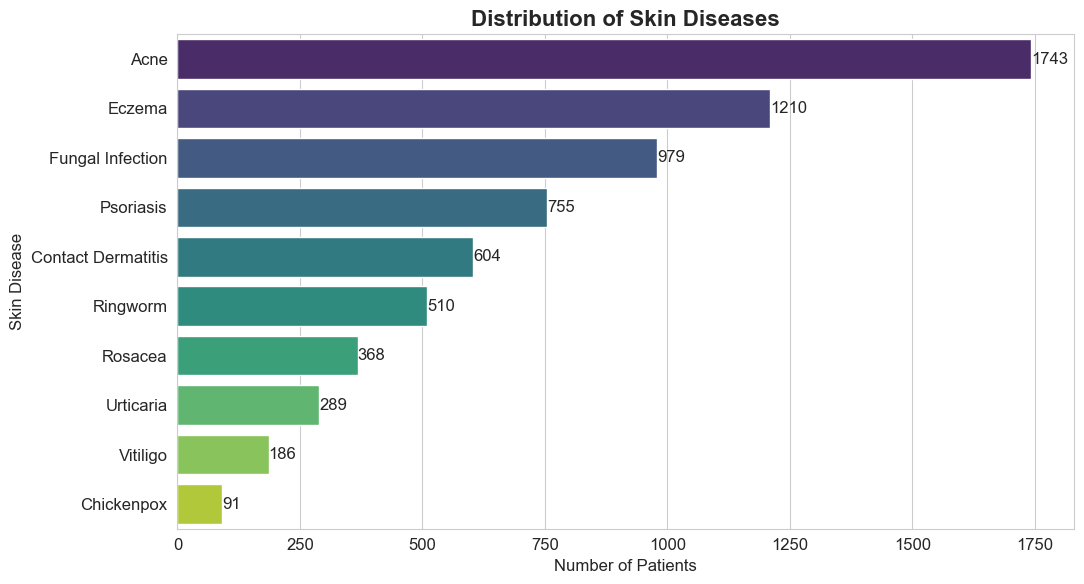

In [3]:
disease_counts = df["disease"].value_counts()

plt.figure(figsize=(11,6))

ax = sns.countplot(
    data=df,
    y="disease",
    order=disease_counts.index,
    palette="viridis"
)

# Add Count Labels
for i in ax.containers:
    ax.bar_label(i)

plt.title("Distribution of Skin Diseases", fontsize=16, weight="bold")
plt.xlabel("Number of Patients")
plt.ylabel("Skin Disease")

plt.tight_layout()
plt.savefig("../images/target_variable_distribution.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

### Observation

- **Acne** has the highest number of patient records.
- **Chickenpox** has the lowest representation in the dataset.
- The target variable is **moderately imbalanced**, which justifies evaluating models using Precision, Recall and F1-score instead of accuracy alone.

# 2. Age Distribution of Patients

### Business Question

**What is the age distribution of patients suffering from skin diseases?**

This helps identify whether skin diseases are concentrated in a particular age group.

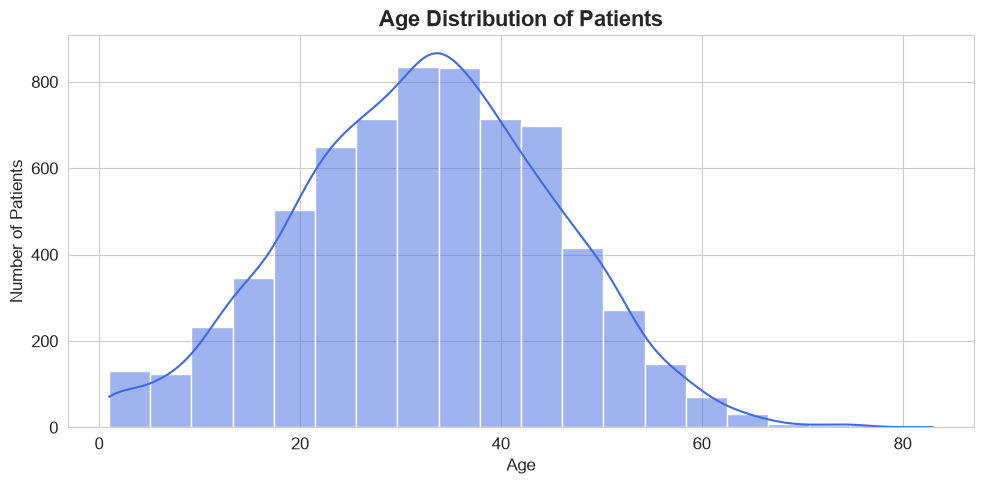

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    color="royalblue"
)

plt.title("Age Distribution of Patients", fontsize=16, weight="bold")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

### Observation

- Patient ages are spread across a wide range.
- Most patients fall within the **young adult and middle-age** category.
- The distribution appears reasonably balanced with no significant gaps.

# 3. Gender Distribution

### Business Question

**How are patient records distributed across different genders?**

This helps determine whether the dataset is gender-balanced.

C:\Users\ABC\AppData\Local\Temp\ipykernel_17964\2043057442.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


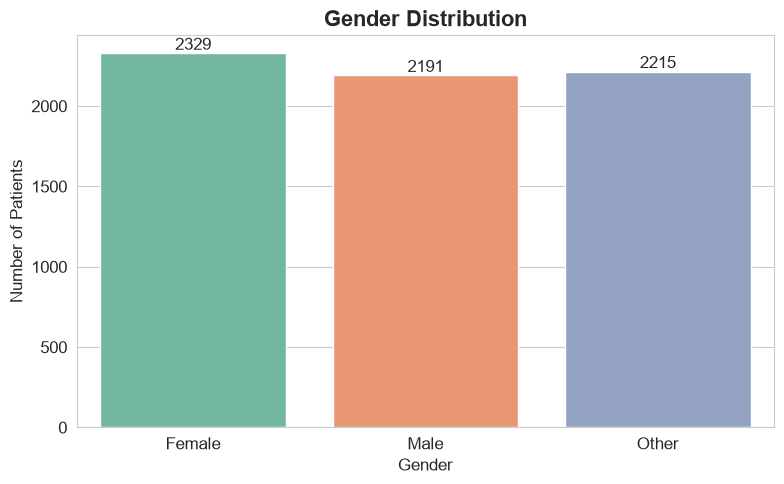

In [5]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df,
    x="gender",
    palette="Set2"
)

for i in ax.containers:
    ax.bar_label(i)

plt.title("Gender Distribution", fontsize=16, weight="bold")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

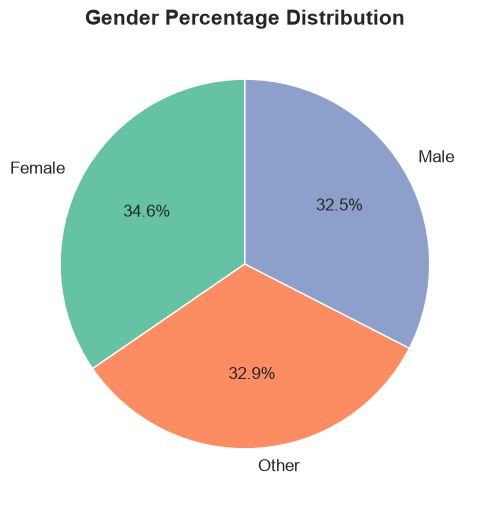

In [6]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2")
)

plt.title("Gender Percentage Distribution", fontsize=15, weight="bold")

plt.show()

### Observation

- Male, Female, and Other categories have a nearly balanced distribution.
- The dataset is not biased toward a single gender.

# 4. Most Affected Body Areas

### Business Question

**Which body areas are most commonly affected by skin diseases?**

This helps identify the anatomical regions with the highest frequency of skin conditions.

C:\Users\ABC\AppData\Local\Temp\ipykernel_17964\25856967.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


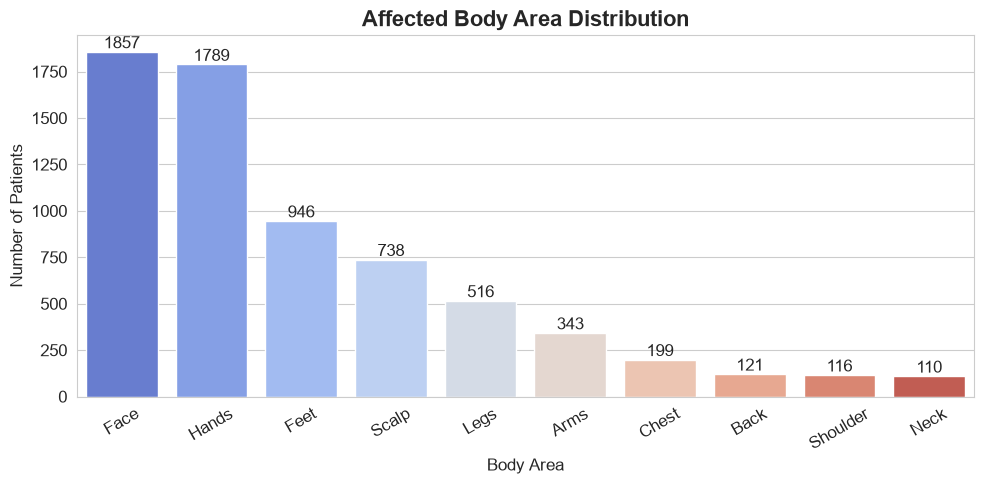

In [7]:
body_counts = df["body_area"].value_counts()

plt.figure(figsize=(10,5))

ax = sns.countplot(
    data=df,
    x="body_area",
    order=body_counts.index,
    palette="coolwarm"
)

for i in ax.containers:
    ax.bar_label(i)

plt.xticks(rotation=30)

plt.title("Affected Body Area Distribution", fontsize=16, weight="bold")
plt.xlabel("Body Area")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

### Observation

- Face and Hands are the most frequently affected body areas.
- Chest, Neck, Shoulder and Back have comparatively fewer cases.

# 5. Distribution of Rash Types

### Business Question

**Which rash types are most common among patients?**

Rash type is one of the most important symptoms for predicting skin diseases.

C:\Users\ABC\AppData\Local\Temp\ipykernel_17964\1592714874.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


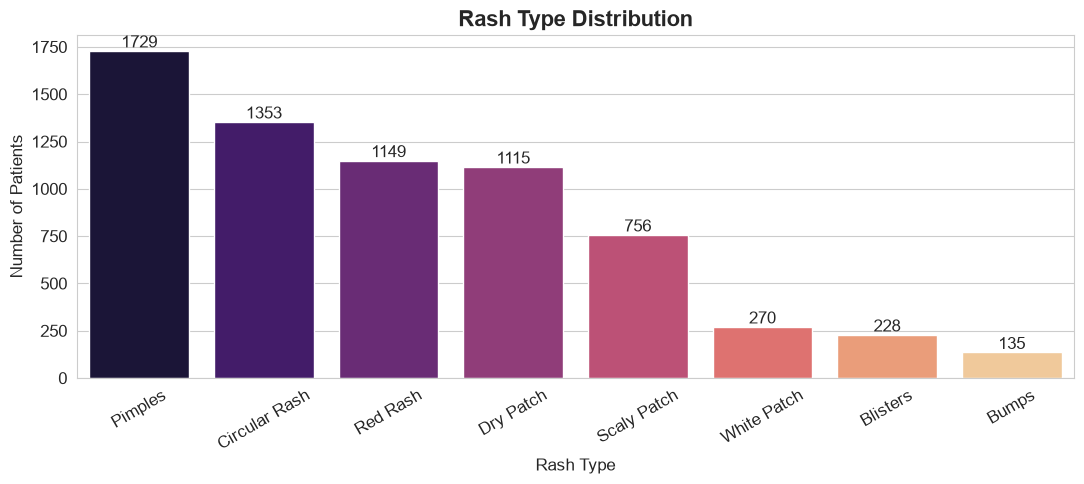

In [8]:
rash_counts = df["rash_type"].value_counts()

plt.figure(figsize=(11,5))

ax = sns.countplot(
    data=df,
    x="rash_type",
    order=rash_counts.index,
    palette="magma"
)

for i in ax.containers:
    ax.bar_label(i)

plt.xticks(rotation=30)

plt.title("Rash Type Distribution", fontsize=16, weight="bold")
plt.xlabel("Rash Type")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

### Observation

- Pimples are the most frequently observed rash type.
- Circular Rash and Red Rash also appear frequently.
- Blisters and Bumps have the lowest occurrence.

# 6. Correlation Heatmap

### Business Question

**Which numerical features are correlated with each other?**

Correlation helps identify relationships between health measurements and symptom severity.

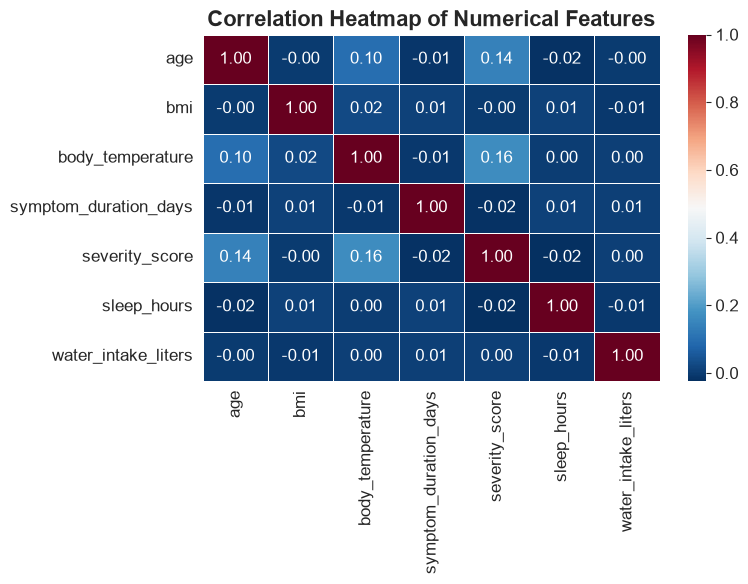

In [9]:
numerical_cols = [
    "age",
    "bmi",
    "body_temperature",
    "symptom_duration_days",
    "severity_score",
    "sleep_hours",
    "water_intake_liters"
]

corr = df[numerical_cols].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="RdBu_r",
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=16, weight="bold")

plt.tight_layout()
plt.show()

### Observation

- Most numerical variables have weak-to-moderate correlations.
- Severity Score and Symptom Duration show a positive relationship.
- Water Intake and Sleep Hours have relatively weak correlation with other variables.

# 7. Severity Score by Disease

### Business Question

**How does disease severity vary across different skin diseases?**

Boxplots help visualize the spread, median, and outliers in severity scores.

C:\Users\ABC\AppData\Local\Temp\ipykernel_17964\479299236.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


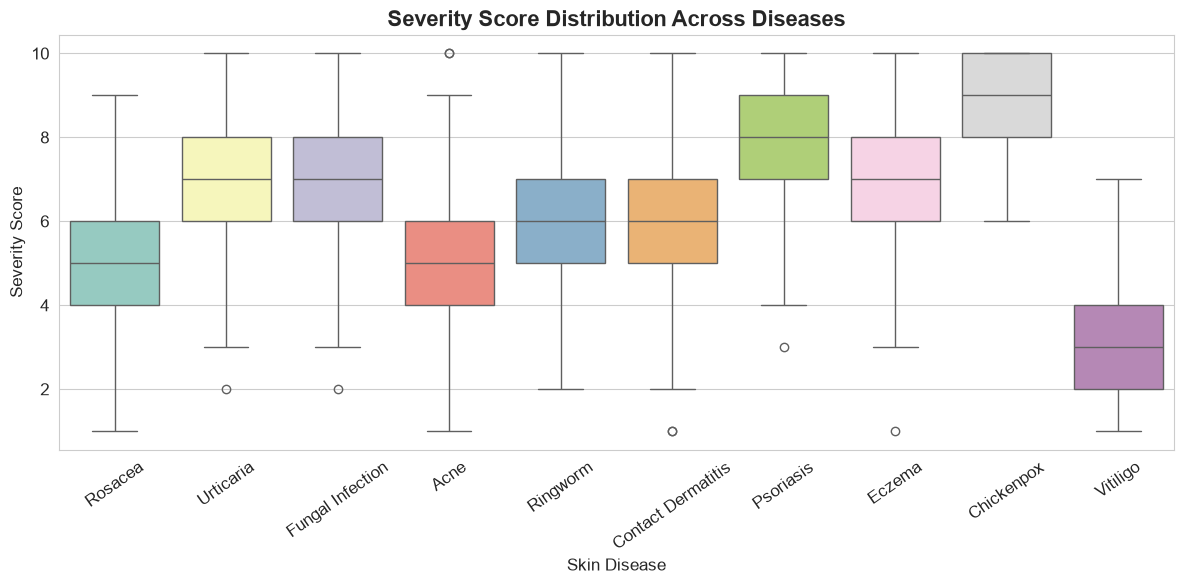

In [10]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="disease",
    y="severity_score",
    palette="Set3"
)

plt.xticks(rotation=35)

plt.title("Severity Score Distribution Across Diseases", fontsize=16, weight="bold")
plt.xlabel("Skin Disease")
plt.ylabel("Severity Score")

plt.tight_layout()
plt.show()

### Observation

- Different diseases exhibit different severity ranges.
- Some diseases have wider variability in severity, indicating mild to severe cases.
- The boxplot also highlights outliers in severity scores.

# 8. BMI Distribution

### Business Question

**What is the distribution of Body Mass Index (BMI) among patients?**

BMI is included as a numerical health feature that may influence skin conditions.

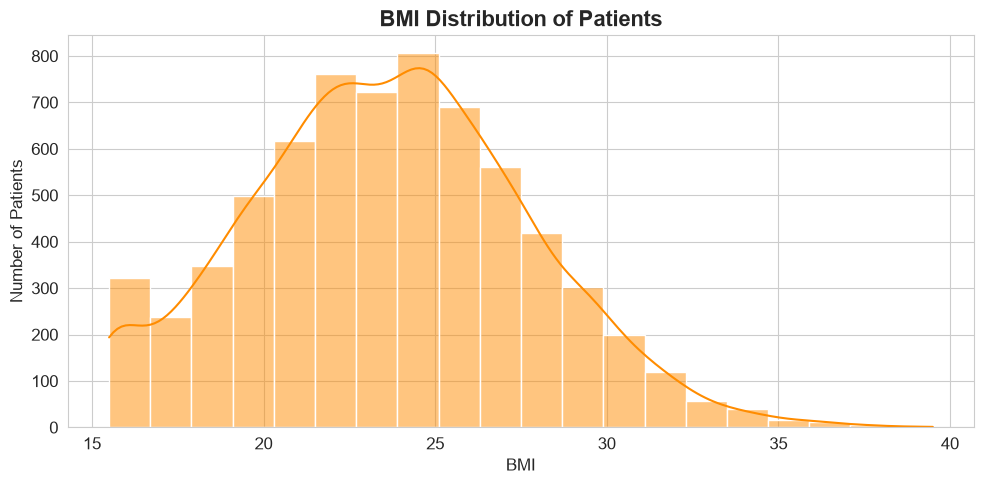

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x="bmi",
    bins=20,
    kde=True,
    color="darkorange"
)

plt.title("BMI Distribution of Patients", fontsize=16, weight="bold")
plt.xlabel("BMI")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

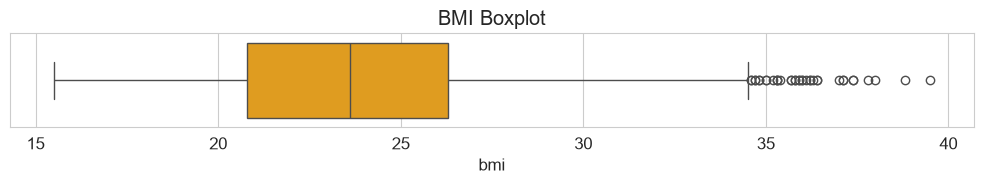

In [12]:
plt.figure(figsize=(10,2))

sns.boxplot(
    x=df["bmi"],
    color="orange"
)

plt.title("BMI Boxplot")

plt.tight_layout()
plt.show()

### Observation

- BMI values are distributed around the healthy-to-overweight range.
- A few outliers exist, which were handled during preprocessing before model training.

# EDA Summary

## Key Insights from the Dataset

- The cleaned dataset contains **6,735 patient records** and **27 features**.
- Acne is the most common skin disease, while Chickenpox has the fewest observations.
- The dataset has a nearly balanced gender distribution across Male, Female, and Other categories.
- Face and Hands are the most commonly affected body areas.
- Pimples, Circular Rash, and Red Rash are the most frequent rash types.
- Severity Score varies significantly across different skin diseases.
- Numerical features such as Age, BMI, Body Temperature, and Symptom Duration provide meaningful information for disease prediction.
- The dataset is suitable for multiclass machine learning classification after preprocessing and feature engineering.